# Chapter 3 — Maps Over Time: Watching the Lines Move

In Chapter 2 we measured one map with numbers. Now we **draw** the maps — North Carolina in 2016, 2020, and 2024 — and watch the lines move.

## Why these three years?

District boundaries are redrawn every ten years after the Census — but courts can force a redraw in between. North Carolina is a perfect case study because its map changed for **all three** elections:

- **2016:** a court-ordered remedial map (after the 2011 map was struck down).
- **2020:** another court-ordered redraw from 2019.
- **2024:** a brand-new map after the 2020 Census, plus a 2023 redraw — and a 14th seat, gained because the state's population grew.

## The shapefiles, in plain words

A **shapefile** is a file that stores the outline of every district as a polygon. We use the U.S. Census Bureau's **cartographic boundary files** at 1:20,000,000 scale — a simplified, small-file version made exactly for thematic maps like this one. Each election gets the file for its Congress:

- 2016 election → 115th Congress file (2017 vintage)
- 2020 election → 116th Congress file (2020 vintage, which captures the November 2019 redraw)
- 2024 election → 119th Congress file (2025 vintage)

Source: https://www.census.gov/geographies/mapping-files/time-series/geo/carto-boundary-file.html


In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib geopandas

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import os
import zipfile
import io
import csv
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

DATA = '../data/raw'
SHAPES = {
    2016: ('cb_2017_us_cd115_20m.zip',
           'https://www2.census.gov/geo/tiger/GENZ2017/shp/cb_2017_us_cd115_20m.zip',
           'CD115FP'),
    2020: ('cb_2020_us_cd116_20m.zip',
           'https://www2.census.gov/geo/tiger/GENZ2020/shp/cb_2020_us_cd116_20m.zip',
           'CD116FP'),
    2024: ('cb_2025_us_cd119_20m.zip',
           'https://www2.census.gov/geo/tiger/GENZ2025/shp/cb_2025_us_cd119_20m.zip',
           'CD119FP'),
}

for year, (fname, url, _) in SHAPES.items():
    path = os.path.join(DATA, fname)
    if os.path.exists(path):
        print(f'{year}: using local {fname}')
    else:
        print(f'{year}: downloading {url}')
        import urllib.request
        urllib.request.urlretrieve(url, path)
        print(f'{year}: saved {fname}')

2016: using local cb_2017_us_cd115_20m.zip
2020: using local cb_2020_us_cd116_20m.zip
2024: using local cb_2025_us_cd119_20m.zip


## Step 1 — Load the maps, keep only North Carolina

The national files contain all 435 districts. We filter to North Carolina (state FIPS code `37`) and keep the district-number column for each Congress.


In [3]:
nc_maps = {}
for year, (fname, _, dist_col) in SHAPES.items():
    gdf = gpd.read_file(f'zip://{DATA}/{fname}')
    nc = gdf[gdf['STATEFP'] == '37'].copy()
    nc['district'] = nc[dist_col].astype(int)
    nc_maps[year] = nc[['district', 'geometry']]
    print(f'{year}: {len(nc)} districts loaded')

# Sanity check the story: did the lines actually move between 2016 and 2020?
m = nc_maps[2016].merge(nc_maps[2020], on='district', suffixes=('_16', '_20'))
same = sum(1 for _, r in m.iterrows() if r['geometry_16'].equals_exact(r['geometry_20'], 0.001))
print(f'\nDistricts with identical shape in 2016 and 2020: {same} of {len(m)}')
print(f'Districts redrawn between the two elections: {len(m) - same}')

2016: 13 districts loaded
2020: 13 districts loaded
2024: 14 districts loaded

Districts with identical shape in 2016 and 2020: 2 of 13
Districts redrawn between the two elections: 11


## Step 2 — Who won each district?

Winners come from MIT Election Data + Science Lab district returns:

- **2016 and 2020:** the TidyTuesday mirror of the MIT file (1976–2022), a clean CSV.
- **2024:** the MIT 1976–2024 file (Harvard Dataverse DOI 10.7910/DVN/IG0UN2). Direct Dataverse download is blocked by a guestbook form, so we use a public mirror of the same file — and we cross-check it: it reproduces the 2016 result (10R/3D) and the 2020 result (8R/5D) exactly, and its 2024 result (10R/4D) matches the official seat count.

One data quirk, documented honestly: the mirror file wraps every row in quotation marks, and 56 of 33,805 rows are malformed (extra commas inside a field). The loader below skips those rows — 0.17% of the file — and the cross-check above shows the North Carolina results are unaffected.


In [4]:
def read_house_tidytuesday():
    path = os.path.join(DATA, 'house_tidytuesday_1976_2022.csv')
    if not os.path.exists(path):
        import urllib.request
        url = ('https://raw.githubusercontent.com/rfordatascience/tidytuesday/'
               'master/data/2023/2023-11-07/house.csv')
        print('Downloading TidyTuesday MIT file...')
        urllib.request.urlretrieve(url, path)
    return pd.read_csv(path, low_memory=False)


def read_house_mirror_2024():
    """Tolerant reader for the quoted-rows mirror of the MIT 1976-2024 file."""
    path = os.path.join(DATA, 'house_1976_2024.csv')
    if not os.path.exists(path):
        import urllib.request
        url = ('https://raw.githubusercontent.com/keithpotz/Election-Prediction/'
               'main/src/data/polling_data/house_1976_2024.csv')
        print('Downloading MIT 1976-2024 mirror file...')
        urllib.request.urlretrieve(url, path)
    with open(path, newline='') as f:
        lines = f.readlines()
    header = lines[0].strip().split(',')
    rows, skipped = [], 0
    for ln in lines[1:]:
        s = ln.strip()
        if s.startswith('"') and s.endswith('"'):
            s = s[1:-1]
        try:
            r = next(csv.reader(io.StringIO(s)))
        except Exception:
            skipped += 1
            continue
        if len(r) != 20:
            skipped += 1
            continue
        rows.append(r)
    print(f'Mirror file: {len(rows)} rows parsed, {skipped} malformed rows skipped')
    return pd.DataFrame(rows, columns=header)


def district_winners(frame, year):
    """Winner (DEMOCRAT/REPUBLICAN/other) per district for one state-year."""
    sub = frame[(frame['state_po'] == 'NC') & (frame['office'] == 'US HOUSE')
                & (frame['stage'] == 'GEN') & (frame['year'].astype(str) == str(year))]
    sub = sub.copy()
    sub['candidatevotes'] = pd.to_numeric(sub['candidatevotes'], errors='coerce')
    win = sub.loc[sub.groupby('district')['candidatevotes'].idxmax()]
    return dict(zip(win['district'].astype(int), win['party']))


tt = read_house_tidytuesday()
w16 = district_winners(tt, 2016)
w20 = district_winners(tt, 2020)
mirror = read_house_mirror_2024()
w24 = district_winners(mirror, 2024)

for year, w in [(2016, w16), (2020, w20), (2024, w24)]:
    d = sum(1 for p in w.values() if p == 'DEMOCRAT')
    r = sum(1 for p in w.values() if p == 'REPUBLICAN')
    print(f'{year}: {len(w)} districts -> {d} Democrat, {r} Republican')

Mirror file: 33749 rows parsed, 56 malformed rows skipped
2016: 13 districts -> 3 Democrat, 10 Republican
2020: 13 districts -> 5 Democrat, 8 Republican
2024: 14 districts -> 4 Democrat, 10 Republican


## Step 3 — Draw the three maps

Blue = Democrat won the district. Red = Republican won it. Compare the shapes, not just the colors: whole regions change hands between elections because the lines moved.


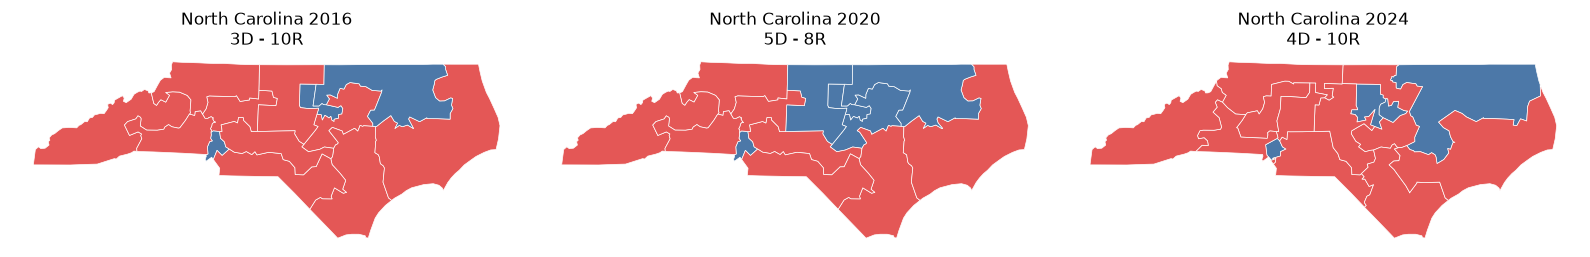

Chart saved to charts/phase3_nc_maps_2016_2020_2024.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, year, winners in [(axes[0], 2016, w16), (axes[1], 2020, w20), (axes[2], 2024, w24)]:
    gdf = nc_maps[year].copy()
    gdf['winner'] = gdf['district'].map(winners)
    gdf['color'] = gdf['winner'].map({'DEMOCRAT': '#4c78a8', 'REPUBLICAN': '#e45756'})
    gdf.plot(ax=ax, color=gdf['color'], edgecolor='white', linewidth=0.5)
    ax.set_title(f'North Carolina {year}\n{sum(1 for p in winners.values() if p == "DEMOCRAT")}D - '
                 f'{sum(1 for p in winners.values() if p == "REPUBLICAN")}R', fontsize=12)
    ax.axis('off')
plt.tight_layout()
plt.savefig('../charts/phase3_nc_maps_2016_2020_2024.png', dpi=150)
plt.show()
print('Chart saved to charts/phase3_nc_maps_2016_2020_2024.png')

## Checkpoint — what you now know

- How to read a Census shapefile and plot real district boundaries.
- North Carolina's map changed in all three elections: 11 of 13 districts were redrawn between 2016 and 2020 alone, and the state gained a 14th district by 2024.
- The seat counts moved with the lines: 3D–10R in 2016, 5D–8R in 2020, 4D–10R in 2024 — while the underlying voters changed far less than the maps did.

Next chapter: the headline finding. Was North Carolina unusual — or is the whole country losing competitive elections? We answer that with every House election from 1976 to 2024.
